# Vertical Coherence

In [1]:
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
from dotenv import find_dotenv, load_dotenv
from tqdm import tqdm
from matplotlib import lines as mlines

from n23_fluctuations_ragland import tools

import scipy

load_dotenv(find_dotenv())

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = 'retina'

## Figure Settings

In [2]:
whoi_colors = ['#00B7BD', '#EE5340', '#0069b1', '#041e42']

plt.rcParams["font.size"] = 8
plt.rcParams["text.usetex"] = True

## estimate observed vertical coherence

In [3]:
fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/wavefront_values.pkl"

with open(fn, "rb") as f:
    wavefront_values = pickle.load(f)

In [4]:
MC = {}
AC = {}
MC_var = {}

for k, ray_id in enumerate(wavefront_values.keys()):
    dz, MC[ray_id], MC_var[ray_id],_,_ = tools.estimate_mutual_coherence(
        wavefront_values[ray_id], 9, omit_zero_lag=False, norm=False
    )

    _, AC[ray_id], _,_,_ = tools.estimate_mutual_coherence(
        np.abs(wavefront_values[ray_id]), 9
    )

In [5]:
def exp_coherence(dz, z0, A):
    return A * np.exp(-0.5 * (dz / z0) ** 2)

def residuals(params, dz, gamma):
    z0, A = params
    return exp_coherence(dz, z0, A) - gamma

A0s = {}
z0s = {}

for k, ray_id in enumerate(wavefront_values.keys()):
    result = scipy.optimize.least_squares(
        residuals,
        x0=[100, 4e11],
        args=(dz[1:], MC[ray_id][1:]),
        bounds=([0, 0], [np.inf, np.inf]),
        x_scale="jac",  # z0 ~ 1e2 and A ~ 1e11 differ by many orders of magnitude
    )

    z0s[ray_id], A0s[ray_id] = result.x

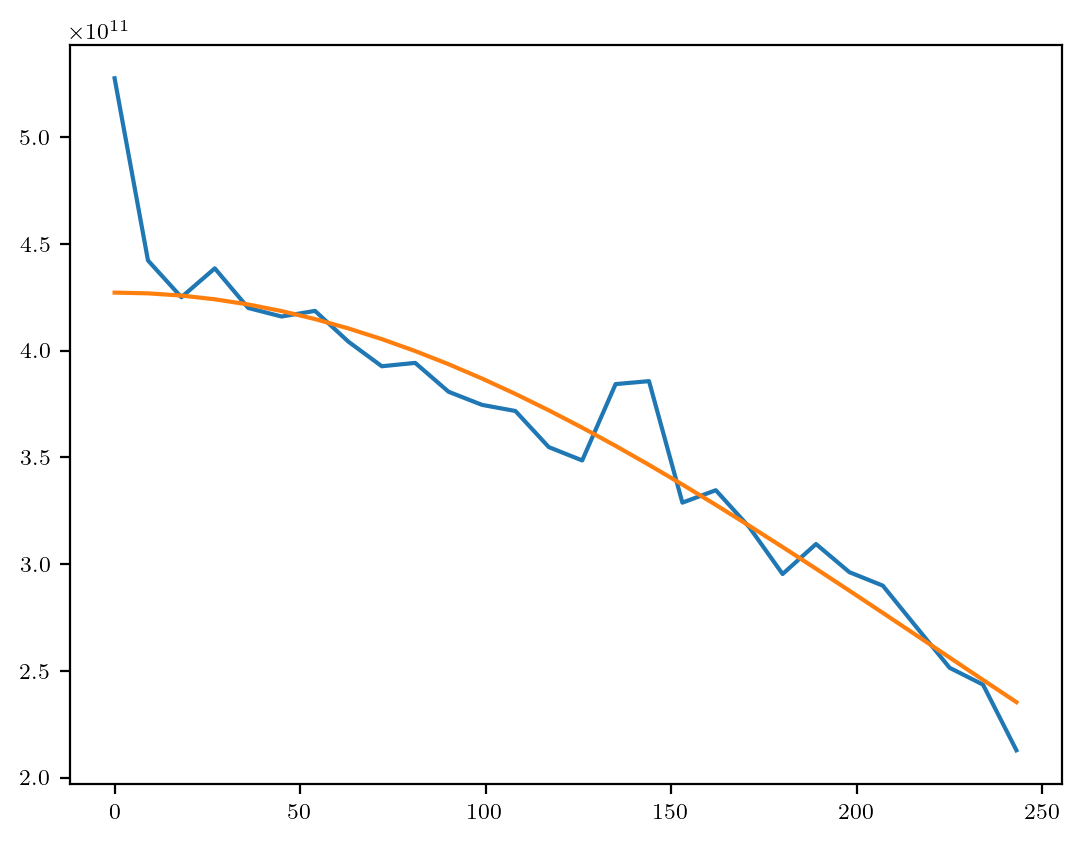

In [6]:
ray_id = '+6'
plt.plot(dz, MC[ray_id])
plt.plot(dz, exp_coherence(dz, z0s[ray_id], A0s[ray_id]))

## compute path integral vertical coherence

In [14]:
latitude = 39.192499999
Omega = 7.292115e-5  # Earth Rotation Speed [rad/s]
f = 2 * Omega * np.sin(np.radians(latitude))  # [rad/s]

zeta0 = 7.3 * np.sqrt(1)
rvs = tools.compute_n23_ray_variables(f=f, zeta0=zeta0)

delta_zr = np.linspace(0, 500, 200)

Dzs = {}

#for ray_id in tqdm(wavefront_values.keys()):
for ray_id in tqdm(rvs.keys()):
    Dzs[ray_id] = []
    for rv in rvs[ray_id]:
        Dzs[ray_id].append(tools.compute_phase_structure_function(rv, delta_zr)[0])

/home/john.ragland/Code/NESMA/NESCAFE23/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)
100%|██████████| 26/26 [01:25<00:00,  3.30s/it]


In [15]:
latitude = 39.192499999
Omega = 7.292115e-5  # Earth Rotation Speed [rad/s]
f = 2 * Omega * np.sin(np.radians(latitude))  # [rad/s]

zeta0 = 7.3 * np.sqrt(2)
rvs = tools.compute_n23_ray_variables(f=f, zeta0=zeta0)

delta_zr = np.linspace(0, 500, 200)

Dzs2 = {}

#for ray_id in tqdm(wavefront_values.keys()):
for ray_id in tqdm(rvs.keys()):
    Dzs2[ray_id] = []
    for rv in rvs[ray_id]:
        Dzs2[ray_id].append(tools.compute_phase_structure_function(rv, delta_zr)[0])

/home/john.ragland/Code/NESMA/NESCAFE23/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)
100%|██████████| 26/26 [00:42<00:00,  1.63s/it]


## Make Plot for ducted

In [16]:
MC_var[ray_id].shape, MC[ray_id].shape, dz.shape

((28,), (28,), (28,))

<ErrorbarContainer object of 3 artists>

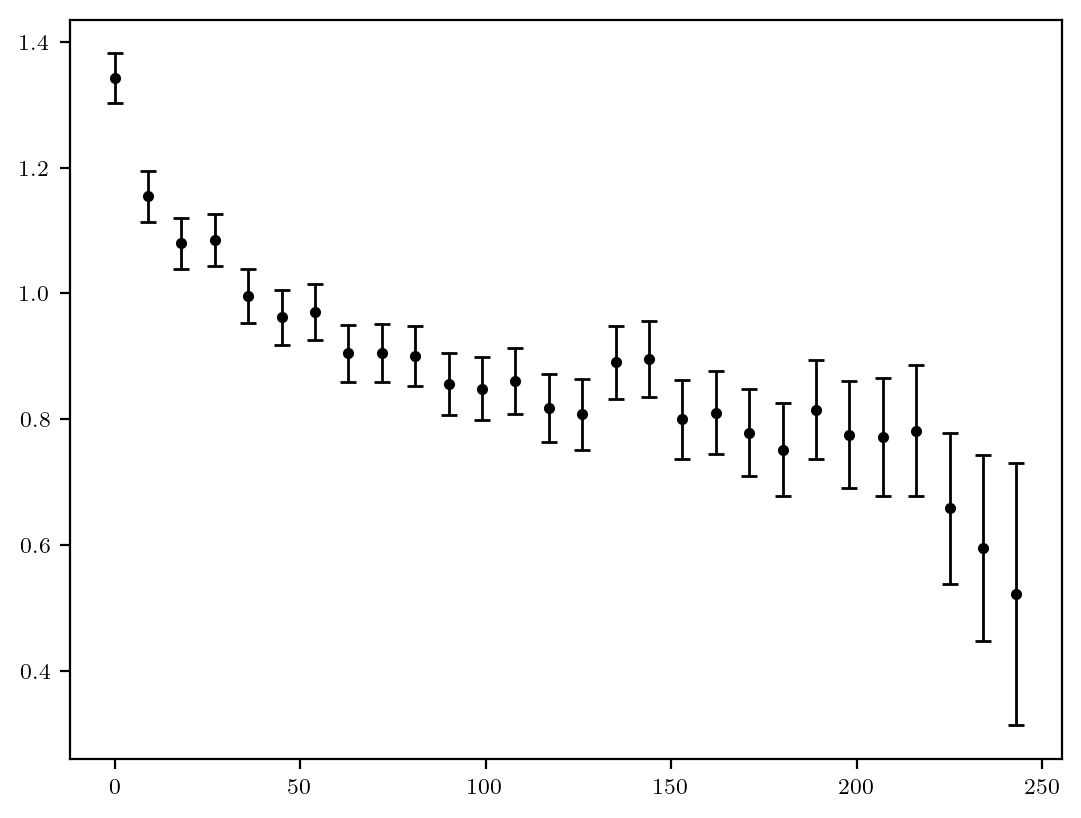

In [17]:
ray_id = '+7'

plt.errorbar(
    dz,
    MC[ray_id]/A0s[ray_id],
    np.sqrt(MC_var[ray_id]),
    elinewidth=1,
    lw=0,
    capsize=3,
    marker="o",
    markersize=3,
    color='k',
    zorder=100,
)

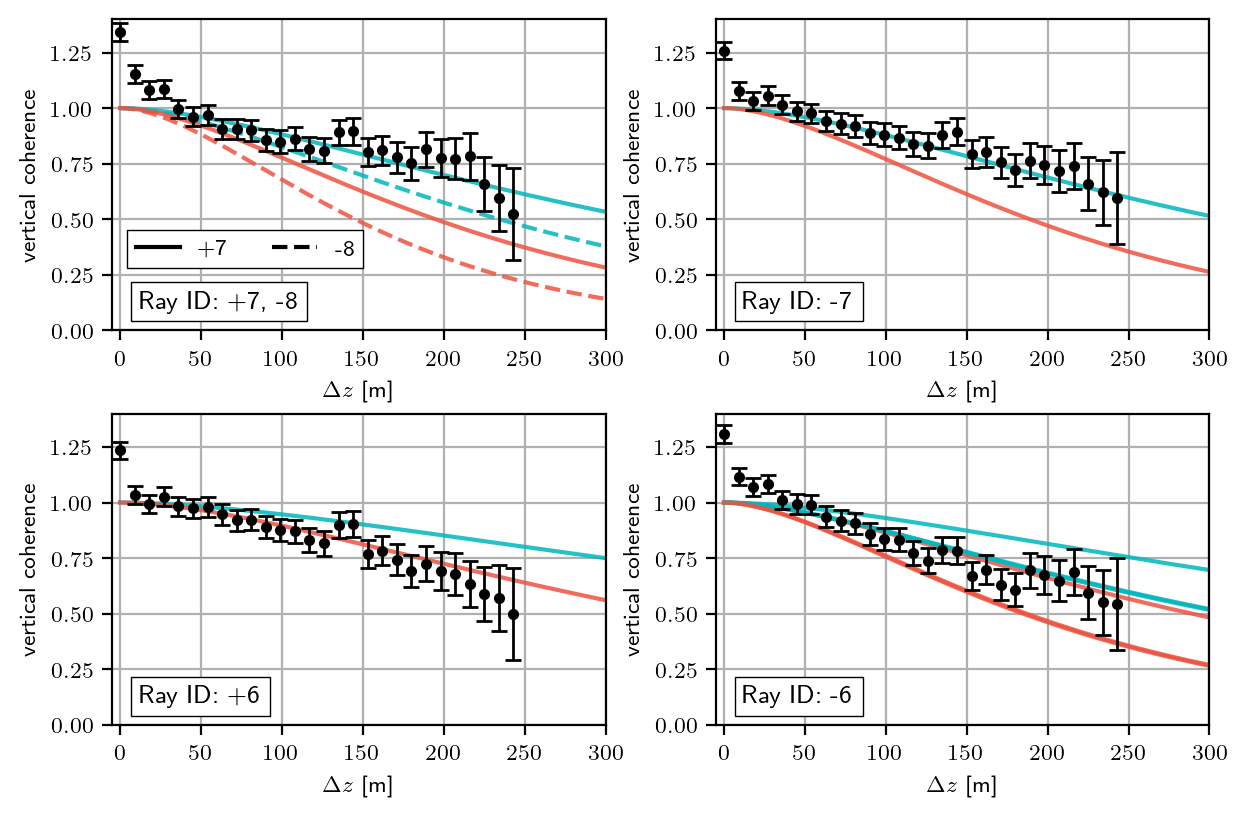

In [21]:
pair_ids = {
    '+7':[0],
    '-7':[0],
    '+6':[0],
    '-6':[0,1,2],
}

fig, axes = plt.subplots(2, 2, figsize=(6.67, 4))
axes = axes.flatten()

ray_ids = ["+7", "-7", "+6", "-6"]

for k, ray_id in enumerate(ray_ids):
    plt.sca(axes[k])

    plt.errorbar(
        dz,
        MC[ray_id]/A0s[ray_id],
        np.sqrt(MC_var[ray_id]),
        elinewidth=1,
        lw=0,
        capsize=3,
        marker="o",
        markersize=3,
        color='k',
        zorder=100,
    )

    plt.ylim([0, 1.4])

    plt.xlabel("$\\Delta z$ [m]")
    plt.ylabel("vertical coherence")

    if ray_id == '+7':
        #plt.text(12, 0.1, f"Ray ID: {ray_id}, -8", fontsize=10)
        plt.text(
            12,
            0.1,
            f"Ray ID: {ray_id}, -8",
            #transform=axes[k].transAxes,
            fontsize=9,
            bbox=dict(facecolor="white", edgecolor="k", pad=3, linewidth=0.5),
        )
        # add legend# Create custom legend handles
        solid_line = mlines.Line2D([], [], color='black', linestyle='-', 
                                   linewidth=1.5, label='+7')
        dashed_line = mlines.Line2D([], [], color='black', linestyle='--', 
                                    linewidth=1.5, label='-8')
        
        # Add the custom legend
        leg = axes[k].legend(handles=[solid_line, dashed_line], ncols=2, loc=(0.03,0.2), framealpha=1, fancybox=False, edgecolor='k')
        leg.get_frame().set_linewidth(0.5)  # <-- thickness here
    else:
        #plt.text(12, 0.1, f"Ray ID: {ray_id}", fontsize=10)
        plt.text(
            12,
            0.1,
            f"Ray ID: {ray_id}",
            #transform=axes[k].transAxes,
            fontsize=9,
            bbox=dict(facecolor="white", edgecolor="k", pad=3, linewidth=0.5),
        )

    for n, pair_id in enumerate(pair_ids[ray_id]):
        if ray_id == '+7':
            plt.plot(delta_zr, np.exp(-Dzs['-8'][pair_id] / 2), c=whoi_colors[0], lw=1.5, linestyle='--', label='-8', alpha=0.85)
            plt.plot(delta_zr, np.exp(-Dzs2['-8'][pair_id] / 2), c=whoi_colors[1], lw=1.5, alpha=0.85, linestyle='--')
            plt.plot(delta_zr, np.exp(-Dzs[ray_id][pair_id] / 2), c=whoi_colors[0], lw=1.5, alpha=0.85, label='+7')
            plt.plot(delta_zr, np.exp(-Dzs2[ray_id][pair_id] / 2), c=whoi_colors[1], lw=1.5, alpha=0.85)

        else:
            plt.plot(delta_zr, np.exp(-Dzs[ray_id][pair_id] / 2), c=whoi_colors[0], lw=1.5, alpha=0.85)
            plt.plot(delta_zr, np.exp(-Dzs2[ray_id][pair_id] / 2), c=whoi_colors[1], lw=1.5, alpha=0.85)
        

    plt.grid()
    plt.xlim([-5, 300])

plt.tight_layout(pad=0.5)

fig.subplots_adjust(right=0.9)


#fig.savefig("../../figures/Ducted_VC.pdf", bbox_inches="tight")

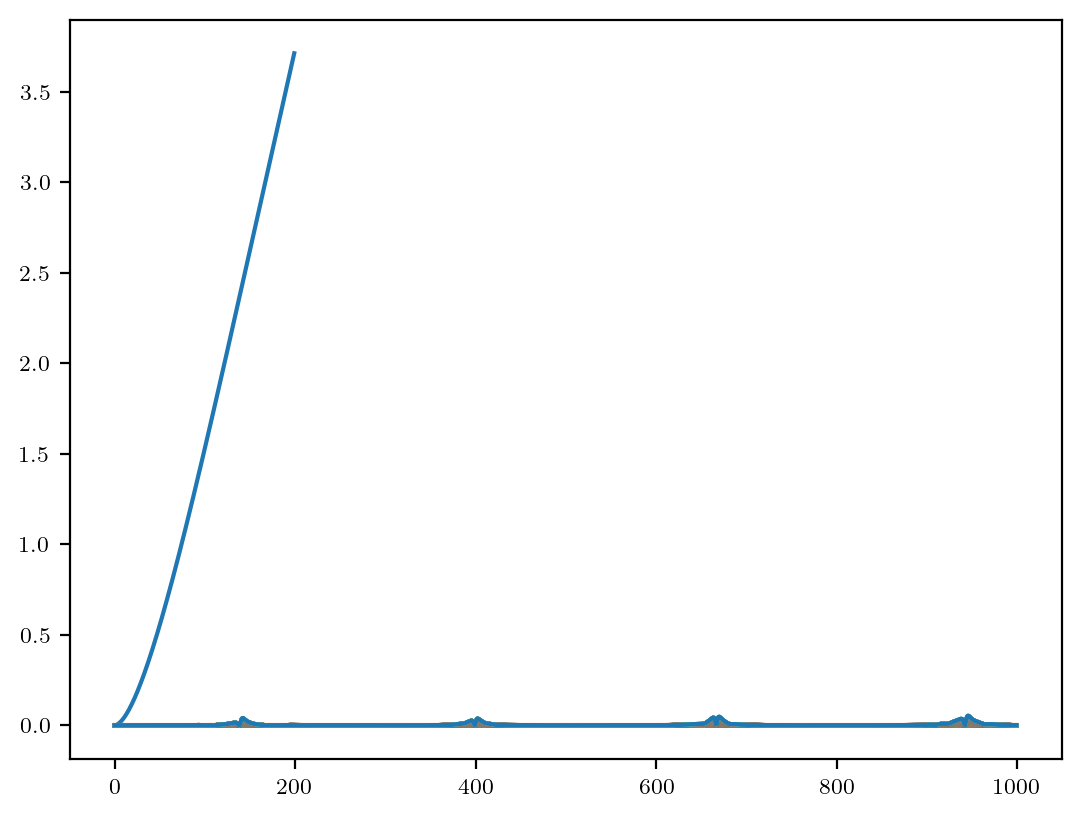

In [14]:
plt.plot(Dzs['-8'][0])
plt.plot(Dzs['-8'][1])

## Make plot for bottom bounces

In [ ]:
plt.rcParams["font.size"] = 9
plt.rcParams["text.usetex"] = True

fig, axes = plt.subplots(5, 4, figsize=(6.67, 7))
axes = axes.flatten()
ray_ids = list(wavefront_values.keys())

for k in range(0, 20):
    ray_id = ray_ids[k + 4]
    plt.sca(axes[k])

    plt.errorbar(
        dz,
        MC[ray_id],
        np.sqrt(MC_var[ray_id]),
        elinewidth=1,
        lw=0,
        capsize=3,
        marker="o",
        markersize=3,
        color="gray",
    )

    plt.ylim([0, 1.1])

    plt.ylabel("vertical coherence")

    plt.text(12, 0.08, f"Ray ID: {ray_id}", fontsize=10)

    for Dz in Dzs[ray_id]:
        plt.plot(delta_zr, np.exp(-Dz / 2), c="k")

    plt.xlim([0, 250])

    if k < 16:
        plt.xlabel("")
        axes[k].set_xticklabels("")
    else:
        plt.xlabel("$\\Delta z$ [m]")
        plt.xticks(np.arange(0, 201, 100))

    if k % 4 == 0:
        plt.ylabel("vertical coherence")
        plt.yticks(np.arange(0.25, 1.1, 0.25))
    else:
        plt.ylabel("")
        axes[k].set_yticklabels("")


plt.tight_layout(pad=0)

#fig.savefig("../../figures/Reflected_VC.pdf", bbox_inches="tight")